Build a basic chatbot using Langgraph (GRAPH API)

In [7]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages

In [8]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]

In [9]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [ ]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm = ChatGroq(model="openai/gpt-oss-20b")

In [11]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.7', 'langchain': '1.4.3'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x111c28590>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x111c292b0>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [12]:
llm = init_chat_model("groq:openai/gpt-oss-20b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.7', 'langchain': '1.4.3'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x111bcec10>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x111bcf610>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [13]:
def chatbot(state:State):
    return {"messages": [llm.invoke(state["messages"])]}

In [14]:
graph_builder = StateGraph(State)

## Adding the main node
graph_builder.add_node("llmchatbot", chatbot)

## Adding Edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot", END)

## Compiling the graph
graph = graph_builder.compile()

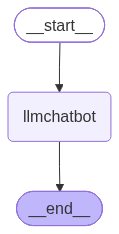

In [15]:
## Visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [16]:
response = graph.invoke({"messages" : "Hi"})

In [17]:
response["messages"][-1].content

'Hello! 👋 How can I help you today?'

In [18]:
for event in graph.stream({"messages" : "Hi, how are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hello! I’m doing great—thanks for asking. How can I help you today?


Chatbot with Tool

In [19]:
from langchain_tavily import TavilySearch 
tool = TavilySearch(max_results=3)
tool.invoke("what is Langgraph?")

{'query': 'what is Langgraph?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how

In [20]:
###Custom Function

def multiply(a:int,b:int) -> int:
    """Multiply a and b and return the result

       Args :
           a : int : first number
           b : int : second number
        Returns :
            int : result of a*b   
    """
    return a*b

In [21]:
tools = [tool, multiply]

In [22]:
llm_with_tools = llm.bind_tools(tools)

In [23]:
llm_with_tools

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.7', 'langchain': '1.4.3'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x111bcec10>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x111bcf610>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and trusted result

In [33]:
 ## Building the Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode, tools_condition

### Defining the State
def tool_calling_llm(state:State):
    return {"messages" : [llm_with_tools.invoke(state["messages"])]}

###Graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

### Adding Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tool_calling_llm", END)

### Compiling the graph
graph = builder.compile()

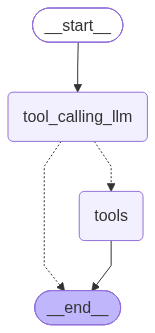

In [34]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [35]:
response = graph.invoke({"messages" : "What is the latest ai news?"})

In [36]:
response

{'messages': [HumanMessage(content='What is the latest ai news?', additional_kwargs={}, response_metadata={}, id='ba1fe41f-ff6a-4713-ba75-2f1e6204c2e0'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to search for latest AI news. Use tavily_search.', 'tool_calls': [{'id': 'fc_951b2efc-97f0-4442-9679-4c19c2c5c3a2', 'function': {'arguments': '{"query":"latest AI news 2026","search_depth":"advanced","time_range":"day","topic":"news"}', 'name': 'tavily_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 59, 'prompt_tokens': 379, 'total_tokens': 438, 'completion_time': 0.064091375, 'completion_tokens_details': {'reasoning_tokens': 15}, 'prompt_time': 0.026257928, 'prompt_tokens_details': None, 'queue_time': 0.395918329, 'total_time': 0.090349303}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e11c8bbf69', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id=

In [37]:
response["messages"][-1].content

'{"query": "latest AI news 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://tech-insider.org/women-ai-job-losses-telephone-operators-pc-history-2026", "title": "Women Face Bigger AI Job Risk, History Shows Why", "content": "14 min read\\n\\nA CNBC report published October 19, 2026, and updated October 20, 2026, has put a sharper point on a question the AI industry has mostly discussed in the abstract: who actually loses their job when the technology lands. The story, titled “Women may be at greater risk of AI job losses. Telephone switch operators and PCs show why,” argues that two prior waves of office automation, the automated telephone switch and the personal computer, hit women’s jobs first and hardest. The implication for 2026 is that generative AI and agentic AI models, which excel at the same routine, pattern-based clerical work that defined those earlier eras, could repeat the pattern at a moment when AI adoption inside companies is

In [38]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the latest ai news?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_951b2efc-97f0-4442-9679-4c19c2c5c3a2)
 Call ID: fc_951b2efc-97f0-4442-9679-4c19c2c5c3a2
  Args:
    query: latest AI news 2026
    search_depth: advanced
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://tech-insider.org/women-ai-job-losses-telephone-operators-pc-history-2026", "title": "Women Face Bigger AI Job Risk, History Shows Why", "content": "14 min read\n\nA CNBC report published October 19, 2026, and updated October 20, 2026, has put a sharper point on a question the AI industry has mostly discussed in the abstract: who actually loses their job when the

In [39]:
response = graph.invoke({"messages" : "What is 200 multiplied by 89?"})

In [41]:
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is 200 multiplied by 89?
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_a30f5a44-9874-4e33-aa1b-e5fc2f6f898a)
 Call ID: fc_a30f5a44-9874-4e33-aa1b-e5fc2f6f898a
  Args:
    a: 200
    b: 89
================================= Tool Message =================================
Name: multiply

17800


In [42]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_352d5b9d-7b1c-4237-8f10-887c4e5bfc54)
 Call ID: fc_352d5b9d-7b1c-4237-8f10-887c4e5bfc54
  Args:
    query: recent AI news
    search_depth: advanced
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-september-2026", "title": "The latest AI news we announced in September 2026", "content": "Speed 0.75X 1X 1.5X 2X\n\n Read AI-generated summary \n\n   Check out the latest AI news from September 2026 in our monthly roundup.\n   Gemini 4 Argon leads our new frontier models with advanced reasoning for comple